## **Nama  : Muhammad Fikri Al Maftuh**
## **NIM   : H061241085**

$$ Tugas 3 $$


## Import Modul
Paket utama: `numpy`, `pandas`, dan `matplotlib`. Jalankan sel secara berurutan. Setiap bagian memuat tujuan, konsep minimum, implementasi, visualisasi bila relevan, serta pemeriksaan sederhana. Pemeriksaan kode tidak otomatis membuktikan validitas ilmiah terhadap fenomena nyata.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
print("Library siap digunakan.")

Library siap digunakan.


## Recipe — Experiment matrix yang dapat direproduksi
**Keterkaitan buku:** R-MOD-003, *Menjalankan Reproducible Experiment Matrix*.

Membandingkan skenario parameter dengan prosedur yang sama. Kondisi awal, kondisi batas, grid, dan durasi dipertahankan; difusivitas termal menjadi parameter yang berubah.

,kappa_m2_s,stability_r,surface_final_C,max_temperature_C,min_temperature_C
0,5.000000e-07,0.015,19.996364,20.222188,18.480252
1,1.000000e-06,0.030,19.996364,20.213317,18.477054
2,1.500000e-06,0.045,19.996364,20.138268,18.475503


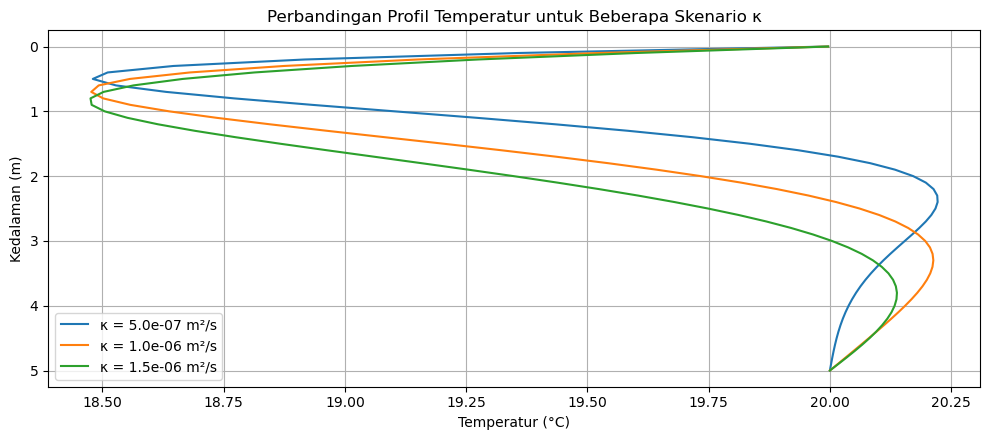

In [11]:
def run_heat_model(kappa_value, days=30, depth_max=5.0, dz=0.1, dt=300.0):
    z_local = np.arange(0, depth_max + dz, dz)
    r_local = kappa_value * dt / dz**2
    if r_local > 0.5:
        raise ValueError(f"Parameter tidak stabil: r={r_local:.3f}")
    temp = np.full_like(z_local, 20.0)
    nsteps = int(days*86400/dt)
    for step in range(nsteps):
        day = step*dt/86400
        temp[0] = 20 + 5*np.sin(2*np.pi*day/30)
        temp_new = temp.copy()
        temp_new[1:-1] = temp[1:-1] + r_local*(temp[2:] - 2*temp[1:-1] + temp[:-2])
        temp_new[-1] = 20.0
        temp = temp_new
    return z_local, temp, r_local

results, profiles = [], {}
for k in [0.5e-6, 1.0e-6, 1.5e-6]:
    zz, tt, rr = run_heat_model(k)
    profiles[k] = (zz, tt)
    results.append({
        "kappa_m2_s": k, "stability_r": rr,
        "surface_final_C": tt[0], "max_temperature_C": tt.max(),
        "min_temperature_C": tt.min()
    })

experiment_summary = pd.DataFrame(results)
display(experiment_summary)

fig, ax = plt.subplots()
for k, (zz, tt) in profiles.items():
    ax.plot(tt, zz, label=f"κ = {k:.1e} m²/s")
ax.invert_yaxis()
ax.set_title("Perbandingan Profil Temperatur untuk Beberapa Skenario κ")
ax.set_xlabel("Temperatur (°C)")
ax.set_ylabel("Kedalaman (m)")
ax.legend()
plt.tight_layout()
plt.show()

## Ringkasan recipe dan batas interpretasi

| Recipe | Implementasi | Output utama |
|---|---|---|
| R-IO-001 / R-QC-001 | Inspeksi data dan kualitas | Missing value, tipe, duplikasi, statistik |
| R-VIS-001 | Visualisasi time series | Grafik suhu terhadap waktu |
| R-ANA-001 | Ringkasan bulanan | Rata-rata dan simpangan baku per bulan |
| R-CAL-001 | Formula menjadi fungsi | Gradien temperatur dan pemeriksaan |
| R-CAL-002 | Anomali baseline | Deret waktu anomali |
| R-CAL-003 | Korelasi lag | Grafik korelasi terhadap lag |
| R-MOD-001 | Difusi panas 1D | Profil temperatur terhadap kedalaman |
| R-MOD-003 | Experiment matrix | Tabel metrik dan perbandingan skenario |

### Catatan akhir
1. Dataset dalam notebook ini sintetis untuk demonstrasi.
2. Plot dan pemeriksaan kode bukan pengganti validasi ilmiah dengan observasi atau solusi referensi.
3. Untuk data nyata, periksa unit, metadata, sumber, rentang waktu, CRS jika spasial, dan aturan penanganan nilai hilang.
4. Ini adalah **pilihan recipe Python lokal**, bukan implementasi seluruh recipe dalam buku. Recipe yang memerlukan API, layanan live, UI, atau integrasi eksternal membutuhkan konfigurasi dan izin terpisah.